In [1]:
import numpy as np
import pandas as pd
import pyarrow.feather as feather
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from scipy.ndimage import gaussian_filter
from scipy import stats
from pathlib import Path

import sys
sys.path.append("../")

from utils import *

In [2]:
sns.set_context("notebook", font_scale=1.15)
plt.rcParams.update({
    "font.family":     "serif",
    "font.size":       14,
    "axes.labelsize":  15,
    "axes.titlesize":  14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi":      120,
    "axes.grid":       True,
    "grid.alpha":      0.35,
    "axes.axisbelow":  True,
})
PALETTE = sns.color_palette("muted")

In [3]:
DATA_DIR      = Path("../data/sweep_2026_04_01_1627/")
EDGE_SAMPLE_N = None          # None → all sims; int → sample that many sim-ids
P_FAKE_SPLIT  = "quartiles"   # "quartiles" | "tertiles" | [b1, b2, ...]
BIN_N         = 20            # bins for binned line plots
PHASE_GRID    = 25            # grid resolution for phase-transition heatmaps
RANDOM_SEED   = 42

PARAM_COLS = ["v_cost", "loss", "tpr", "fpr", "p_fake"]
PARAM_LABELS = {
    "v_cost": "Verification Cost",
    "loss":   "Payoff Loss",
    "tpr":    "True Positive Rate (TPR)",
    "fpr":    "False Positive Rate (FPR)",
    "p_fake": "P(Fake)",
}

In [4]:
def make_regimes(sim_df, split="quartiles"):
    """
    Attach a 'regime' string column to sim_df.
    Returns (sim_df_copy, ordered label list, boundary list).
    """
    pf = sim_df["p_fake"].values
    if split == "quartiles":
        boundaries = list(np.percentile(pf, [25, 50, 75]))
        prefixes   = ["Q1 (Low)", "Q2 (Mid-Low)", "Q3 (Mid-High)", "Q4 (High)"]
    elif split == "tertiles":
        boundaries = list(np.percentile(pf, [33.3, 66.7]))
        prefixes   = ["Low", "Mid", "High"]
    else:
        boundaries = list(split)
        prefixes   = [f"Bin {i+1}" for i in range(len(boundaries) + 1)]

    bounds = [-np.inf] + boundaries + [np.inf]
    n      = len(bounds) - 1
    labels = np.empty(len(pf), dtype=object)
    names  = []
    for i in range(n):
        lo, hi = bounds[i], bounds[i + 1]
        if i == 0:
            name = f"{prefixes[i]} p_fake (< {boundaries[0]:.2f})"
        elif i == n - 1:
            name = f"{prefixes[i]} p_fake (> {boundaries[-1]:.2f})"
        else:
            name = f"{prefixes[i]} p_fake ({boundaries[i-1]:.2f}–{boundaries[i]:.2f})"
        names.append(name)
        mask = (pf > lo) & (pf <= hi)
        labels[mask] = name

    out = sim_df.copy()
    out["regime"] = labels
    return out, names, boundaries

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# LOAD DATA
# ═══════════════════════════════════════════════════════════════════════════
print("Loading simulation and node data …")
sim_df  = feather.read_feather(DATA_DIR / "simulations.arrow")
node_df = feather.read_feather(DATA_DIR / "nodes.arrow")
print(f"  sim_df  : {sim_df.shape}")
print(f"  node_df : {node_df.shape}")

Loading simulation and node data …
  sim_df  : (50000, 13)
  node_df : (15000000, 15)


In [6]:
def compute_normalized_payoff(row):
    rep = row["payoff"]
    best = row["best_payoff"]
    worst = row["worst_payoff"]
    
    if rep < 0 and worst != 0:
        return - (rep / worst)
    elif rep > 0 and best != 0:
        return rep / best
    else:
        return 0.0

node_df["agent_veracity"] = node_df.apply(compute_normalized_payoff, axis=1)

In [8]:
# ── p_fake regimes ────────────────────────────────────────────────────────────
sim_df, REGIME_ORDER, BOUNDARIES = make_regimes(sim_df, P_FAKE_SPLIT)
N_REGIMES     = len(REGIME_ORDER)
REGIME_COLORS = PALETTE[:N_REGIMES]
print(f"  Regimes ({P_FAKE_SPLIT}): {REGIME_ORDER}")

# ── propagate regime & lhs_id onto node_df ───────────────────────────────────
regime_map = dict(zip(sim_df["global_sim_id"], sim_df["regime"]))
lhs_map    = dict(zip(sim_df["global_sim_id"], sim_df["lhs_id"]))
node_df["regime"] = node_df["global_sim_id"].map(regime_map)
node_df["lhs_id"] = node_df["global_sim_id"].map(lhs_map)

  Regimes (quartiles): ['Q1 (Low) p_fake (< 0.30)', 'Q2 (Mid-Low) p_fake (0.30–0.50)', 'Q3 (Mid-High) p_fake (0.50–0.70)', 'Q4 (High) p_fake (> 0.70)']


In [9]:
# compute sen welfare per simulation
sen_values = (
    node_df
    .groupby("global_sim_id")["agent_veracity"]
    .apply(lambda x: sen_welfare(x.values))
    .reset_index()
    .rename(columns={"agent_veracity": "sen_welfare"})
)

sim_df = sim_df.merge(sen_values, on="global_sim_id")

In [10]:
def prcc(X: pd.DataFrame, y: np.ndarray) -> pd.DataFrame:
    """
    Partial Rank Correlation Coefficient for each column of X against y.

    For each input Xi:
      1. Rank-transform all inputs and y.
      2. Regress ranked-Xi on all other ranked inputs → residuals e_Xi.
      3. Regress ranked-y  on all other ranked inputs → residuals e_y.
      4. Pearson r(e_Xi, e_y) = PRCC_i.

    Significance via t = PRCC * sqrt((n-2)/(1-PRCC²)), df = n-2, two-sided.
    Returns DataFrame with columns: prcc, t_stat, p_value.
    """
    n, k = X.shape
    Xr   = X.apply(lambda col: stats.rankdata(col)) # rank each column
    yr   = stats.rankdata(y)
    rows = []

    for i, col in enumerate(X.columns):
        others = [j for j in range(k) if j != i]
        Z      = np.column_stack([np.ones(n), Xr.iloc[:, others].values])

        beta_x, *_ = np.linalg.lstsq(Z, Xr.iloc[:, i].values, rcond=None)
        e_x = Xr.iloc[:, i].values - Z @ beta_x

        beta_y, *_ = np.linalg.lstsq(Z, yr, rcond=None)
        e_y = yr - Z @ beta_y

        r, _   = stats.pearsonr(e_x, e_y)
        df_val = n - 2
        t      = r * np.sqrt(df_val / max(1 - r**2, 1e-12))
        p      = 2 * stats.t.sf(abs(t), df_val)
        rows.append({"param": col, "prcc": r, "t_stat": t, "p_value": p})

    return pd.DataFrame(rows).set_index("param")


  Parameter                     PRCC     t-stat      p-value
  P(Fake)                    -0.7381    -244.64     0.00e+00  ***
  True Positive Rate (TPR)    0.4175     102.73     0.00e+00  ***
  Payoff Loss                -0.3991     -97.31     0.00e+00  ***
  False Positive Rate (FPR)  -0.3368     -79.99     0.00e+00  ***
  Verification Cost          -0.2920     -68.27     0.00e+00  ***


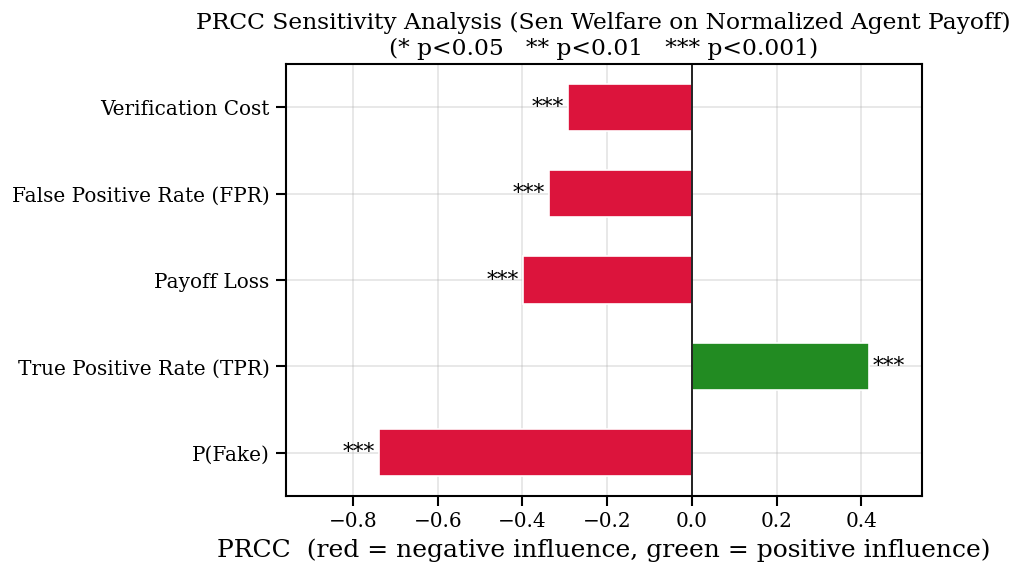

In [11]:
prcc_df = prcc(sim_df[PARAM_COLS], sim_df["sen_welfare"].values)
prcc_df = prcc_df.sort_values("prcc", key=abs, ascending=False)

print(f"\n  {'Parameter':<25} {'PRCC':>8} {'t-stat':>10} {'p-value':>12}")
for param, row in prcc_df.iterrows():
    sig = ("***" if row.p_value < 0.001 else
           "**"  if row.p_value < 0.01  else
           "*"   if row.p_value < 0.05  else "ns")
    print(f"  {PARAM_LABELS[param]:<25} {row.prcc:>8.4f}"
          f" {row.t_stat:>10.2f} {row.p_value:>12.2e}  {sig}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
bar_colors = ["forestgreen" if v > 0 else "crimson" for v in prcc_df["prcc"]]
ax.barh(
    [PARAM_LABELS[p] for p in prcc_df.index],
    prcc_df["prcc"],
    color=bar_colors, edgecolor="white", height=0.55
)
ax.axvline(0, color="black", lw=1.0)

# significance stars next to bars
for i, (param, row) in enumerate(prcc_df.iterrows()):
    sig = ("***" if row.p_value < 0.001 else
           "**"  if row.p_value < 0.01  else
           "*"   if row.p_value < 0.05  else "")
    if sig:
        x_off = 0.01  if row.prcc >= 0 else -0.01
        ha    = "left" if row.prcc >= 0 else "right"
        ax.text(row.prcc + x_off, i, sig, va="center", ha=ha, fontsize=13)

ax.set_xlabel("PRCC  (red = negative influence, green = positive influence)")
ax.set_title("PRCC Sensitivity Analysis (Sen Welfare on Normalized Agent Payoff)\n"
             "(* p<0.05   ** p<0.01   *** p<0.001)")
ax.set_xlim(
    min(prcc_df["prcc"].min() * 1.3, -0.05),
    max(prcc_df["prcc"].max() * 1.3,  0.05),
)
fig.tight_layout()
plt.show()